In [ ]:
%pip install -q tensorflow-datasets scikit-learn pandas matplotlib

In [ ]:
%pip install -q importlib-resources

In [ ]:
import tensorflow as tf
import tensorflow_datasets as tfds
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("TensorFlow version:", tf.__version__)
print("TensorFlow Datasets version:", tfds.__version__)
print("tfds.load available:", hasattr(tfds, "load"))

print("GPU available:", len(tf.config.list_physical_devices("GPU")) > 0)

TensorFlow version: 2.21.0
TensorFlow Datasets version: 4.9.10
tfds.load available: True
GPU available: True


In [ ]:
import tensorflow_datasets as tfds

(train_ds, info) = tfds.load(
    "tf_flowers",
    split="train",
    with_info=True,
    as_supervised=True
)

print("Dataset loaded successfully!")
print("Number of images:", info.splits["train"].num_examples)
print("Number of classes:", info.features["label"].num_classes)
print("Class names:", info.features["label"].names)

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Generating splits...:   0%|          | 0/1 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/tf_flowers/incomplete.658PKZ_3.0.1/tf_flowers-train.tfrecord-[0-9][0-9][0-…

Dataset tf_flowers downloaded and prepared to /root/tensorflow_datasets/tf_flowers/3.0.1. Subsequent calls will reuse this data.
Dataset loaded successfully!
Number of images: 3670
Number of classes: 5
Class names: ['dandelion', 'daisy', 'tulips', 'sunflowers', 'roses']


In [ ]:
import tensorflow as tf
from tensorflow.keras.applications.resnet50 import preprocess_input

IMG_SIZE = 224
BATCH_SIZE = 32

def preprocess_image(image, label):
    image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE))
    image = preprocess_input(image)
    return image, label

train_ds = train_ds.map(
    preprocess_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

train_ds = train_ds.shuffle(1000).batch(BATCH_SIZE)
train_ds = train_ds.prefetch(tf.data.AUTOTUNE)

print("Image preprocessing completed!")
print("Image size:", IMG_SIZE, "x", IMG_SIZE)
print("Batch size:", BATCH_SIZE)

Image preprocessing completed!
Image size: 224 x 224
Batch size: 32


In [ ]:
from tensorflow.keras.applications import ResNet50

base_model = ResNet50(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze pretrained layers
base_model.trainable = False

print("ResNet50 loaded successfully!")
print("Total layers:", len(base_model.layers))
print("Trainable:", base_model.trainable)

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
ResNet50 loaded successfully!
Total layers: 175
Trainable: False


In [ ]:
import tensorflow as tf
from tensorflow.keras.layers import (
    GlobalAveragePooling2D,
    Dense,
    Reshape,
    Multiply,
    Conv2D,
    Lambda,
    Concatenate
)

def channel_attention(input_feature, ratio=8):
    channels = input_feature.shape[-1]

    avg_pool = GlobalAveragePooling2D()(input_feature)
    avg_pool = Reshape((1, 1, channels))(avg_pool)

    shared_dense_1 = Dense(
        channels // ratio,
        activation="relu",
        use_bias=False
    )
    shared_dense_2 = Dense(
        channels,
        activation="sigmoid",
        use_bias=False
    )

    attention = shared_dense_2(shared_dense_1(avg_pool))

    return Multiply()([input_feature, attention])


def spatial_attention(input_feature):
    avg_pool = Lambda(
        lambda x: tf.reduce_mean(x, axis=-1, keepdims=True)
    )(input_feature)

    max_pool = Lambda(
        lambda x: tf.reduce_max(x, axis=-1, keepdims=True)
    )(input_feature)

    concat = Concatenate(axis=-1)([avg_pool, max_pool])

    attention = Conv2D(
        filters=1,
        kernel_size=7,
        padding="same",
        activation="sigmoid",
        use_bias=False
    )(concat)

    return Multiply()([input_feature, attention])


print("Channel and spatial attention functions defined successfully!")

Channel and spatial attention functions defined successfully!


In [ ]:
import tensorflow as tf
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.layers import (
    Input,
    GlobalAveragePooling2D,
    Dense,
    Dropout
)
from tensorflow.keras.models import Model

# Input layer
inputs = Input(shape=(224, 224, 3))

# Pretrained ResNet50 backbone
base_model = ResNet50(
    weights="imagenet",
    include_top=False,
    input_tensor=inputs
)

# Freeze pretrained layers
base_model.trainable = False

# Extract feature maps
x = base_model.output

# Apply channel attention
x = channel_attention(x)

# Convert feature maps into a feature vector
x = GlobalAveragePooling2D()(x)

# Classification layers
x = Dense(256, activation="relu")(x)
x = Dropout(0.5)(x)

# Five flower categories
outputs = Dense(5, activation="softmax")(x)

# Create model
model = Model(inputs=inputs, outputs=outputs)

# Compile model
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_pad           │ (None, 230, 230,  │          0 │ input_layer_1[0]… │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 112, 112,  │      9,472 │ conv1_pad[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 112, 112,  │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 112, 112,  │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pad           │ (None, 114, 114,  │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pool          │ (None, 56, 56,    │          0 │ pool1_pad[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 56, 56,    │      4,160 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 56, 56,    │        256 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 56, 56,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 56, 56,    │     36,928 │ conv2_block1_1_r… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_bn   │ (None, 56, 56,    │        256 │ conv2_block1_2_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_relu │ (None, 56, 56,    │          0 │ conv2_block1_2_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_conv │ (None, 56, 56,    │     16,640 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_conv │ (None, 56, 56,    │     16,640 │ conv2_block1_2_r… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_bn   │ (None, 56, 56,    │      1,024 │ conv2_block1_0_c… │
│ (BatchNormalizatio… │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_bn   │ (None, 56, 56,    │      1,024 │ conv2_block1_3_c

 Total params: 25,162,117 (95.99 MB)

 Trainable params: 1,574,405 (6.01 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [ ]:
import numpy as np
import tensorflow as tf
from sklearn.model_selection import train_test_split

# Collect preprocessed images and labels
images = []
labels = []

for image_batch, label_batch in train_ds.unbatch():
    images.append(image_batch.numpy())
    labels.append(label_batch.numpy())

images = np.array(images, dtype=np.float32)
labels = np.array(labels, dtype=np.int32)

print("Total images:", len(images))
print("Image shape:", images.shape)
print("Labels shape:", labels.shape)

# Split into training and validation sets
X_train, X_val, y_train, y_val = train_test_split(
    images,
    labels,
    test_size=0.2,
    random_state=42,
    stratify=labels
)

print("Training images:", len(X_train))
print("Validation images:", len(X_val))

Total images: 3670
Image shape: (3670, 224, 224, 3)
Labels shape: (3670,)
Training images: 2936
Validation images: 734


In [ ]:
# Train the model
EPOCHS = 5

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=32,
    verbose=1
)

print("Training completed!")

Epoch 1/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 58s 437ms/step - accuracy: 0.8195 - loss: 0.5086 - val_accuracy: 0.8651 - val_loss: 0.3738
Epoch 2/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 11s 124ms/step - accuracy: 0.9131 - loss: 0.2490 - val_accuracy: 0.9033 - val_loss: 0.2587
Epoch 3/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 12s 129ms/step - accuracy: 0.9435 - loss: 0.1644 - val_accuracy: 0.9005 - val_loss: 0.2696
Epoch 4/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 12s 133ms/step - accuracy: 0.9663 - loss: 0.1069 - val_accuracy: 0.9237 - val_loss: 0.2236
Epoch 5/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 12s 134ms/step - accuracy: 0.9799 - loss: 0.0612 - val_accuracy: 0.8842 - val_loss: 0.3557
Training completed!


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)
import numpy as np

# Predict flower classes
y_pred_probs = model.predict(X_val)
y_pred = np.argmax(y_pred_probs, axis=1)

# Calculate accuracy
accuracy = accuracy_score(y_val, y_pred)

print(f"Validation Accuracy: {accuracy * 100:.2f}%")

# Detailed classification report
class_names = [
    "daisy",
    "dandelion",
    "roses",
    "sunflowers",
    "tulips"
]

print("\nClassification Report:")
print(
    classification_report(
        y_val,
        y_pred,
        labels=[0, 1, 2, 3, 4],
        target_names=class_names,
        zero_division=0
    )
)

# Confusion matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_pred))

23/23 ━━━━━━━━━━━━━━━━━━━━ 12s 329ms/step
Validation Accuracy: 88.42%

Classification Report:
              precision    recall  f1-score   support

       daisy       0.90      0.93      0.92       180
   dandelion       0.97      0.90      0.93       126
       roses       0.97      0.71      0.82       160
  sunflowers       0.85      0.98      0.91       140
      tulips       0.77      0.92      0.84       128

    accuracy                           0.88       734
   macro avg       0.89      0.89      0.88       734
weighted avg       0.90      0.88      0.88       734


Confusion Matrix:
[[168   0   0  11   1]
 [  9 113   0   1   3]
 [  6   2 113   8  31]
 [  1   0   1 137   1]
 [  2   1   3   4 118]]


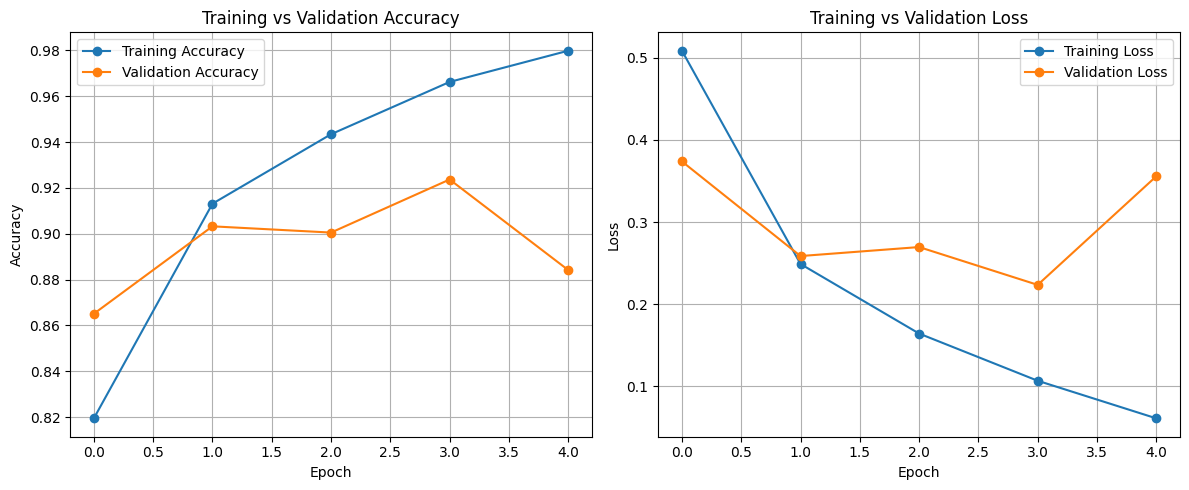

In [ ]:
import matplotlib.pyplot as plt

# Plot training and validation accuracy
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], marker="o", label="Training Accuracy")
plt.plot(history.history["val_accuracy"], marker="o", label="Validation Accuracy")
plt.title("Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

# Plot training and validation loss
plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], marker="o", label="Training Loss")
plt.plot(history.history["val_loss"], marker="o", label="Validation Loss")
plt.title("Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [ ]:
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.layers import (
    Input,
    GlobalAveragePooling2D,
    Dense,
    Dropout
)
from tensorflow.keras.models import Model

# Input layer
inputs = Input(shape=(224, 224, 3))

# Pretrained ResNet50
base_model_spatial = ResNet50(
    weights="imagenet",
    include_top=False,
    input_tensor=inputs
)

# Freeze pretrained layers
base_model_spatial.trainable = False

# Extract feature maps
x = base_model_spatial.output

# Apply spatial attention
x = spatial_attention(x)

# Classification head
x = GlobalAveragePooling2D()(x)
x = Dense(256, activation="relu")(x)
x = Dropout(0.5)(x)
outputs = Dense(5, activation="softmax")(x)

# Build model
spatial_model = Model(inputs=inputs, outputs=outputs)

# Compile
spatial_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

spatial_model.summary()

print("Spatial attention model created successfully!")

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_pad           │ (None, 230, 230,  │          0 │ input_layer_2[0]… │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 112, 112,  │      9,472 │ conv1_pad[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 112, 112,  │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 112, 112,  │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pad           │ (None, 114, 114,  │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pool          │ (None, 56, 56,    │          0 │ pool1_pad[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 56, 56,    │      4,160 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 56, 56,    │        256 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 56, 56,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 56, 56,    │     36,928 │ conv2_block1_1_r… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_bn   │ (None, 56, 56,    │        256 │ conv2_block1_2_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_relu │ (None, 56, 56,    │          0 │ conv2_block1_2_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_conv │ (None, 56, 56,    │     16,640 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_conv │ (None, 56, 56,    │     16,640 │ conv2_block1_2_r… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_bn   │ (None, 56, 56,    │      1,024 │ conv2_block1_0_c… │
│ (BatchNormalizatio… │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_bn   │ (None, 56, 56,    │      1,024 │ conv2_block1_3_c

 Total params: 24,113,639 (91.99 MB)

 Trainable params: 525,927 (2.01 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

Spatial attention model created successfully!


In [ ]:
# Train spatial attention model
EPOCHS = 5

spatial_history = spatial_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=32,
    verbose=1
)

print("Spatial attention training completed!")

Epoch 1/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 44s 325ms/step - accuracy: 0.8052 - loss: 0.5416 - val_accuracy: 0.8624 - val_loss: 0.3373
Epoch 2/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 13s 138ms/step - accuracy: 0.9036 - loss: 0.2747 - val_accuracy: 0.8910 - val_loss: 0.2666
Epoch 3/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 12s 134ms/step - accuracy: 0.9298 - loss: 0.2035 - val_accuracy: 0.8937 - val_loss: 0.2672
Epoch 4/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 22s 147ms/step - accuracy: 0.9414 - loss: 0.1624 - val_accuracy: 0.9019 - val_loss: 0.2714
Epoch 5/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 14s 147ms/step - accuracy: 0.9598 - loss: 0.1195 - val_accuracy: 0.8992 - val_loss: 0.2782
Spatial attention training completed!


===== MODEL COMPARISON =====
Channel Attention - Validation Accuracy: 0.8842
Spatial Attention - Validation Accuracy: 0.8992
Channel Attention - Validation Loss:     0.3557
Spatial Attention - Validation Loss:     0.2782


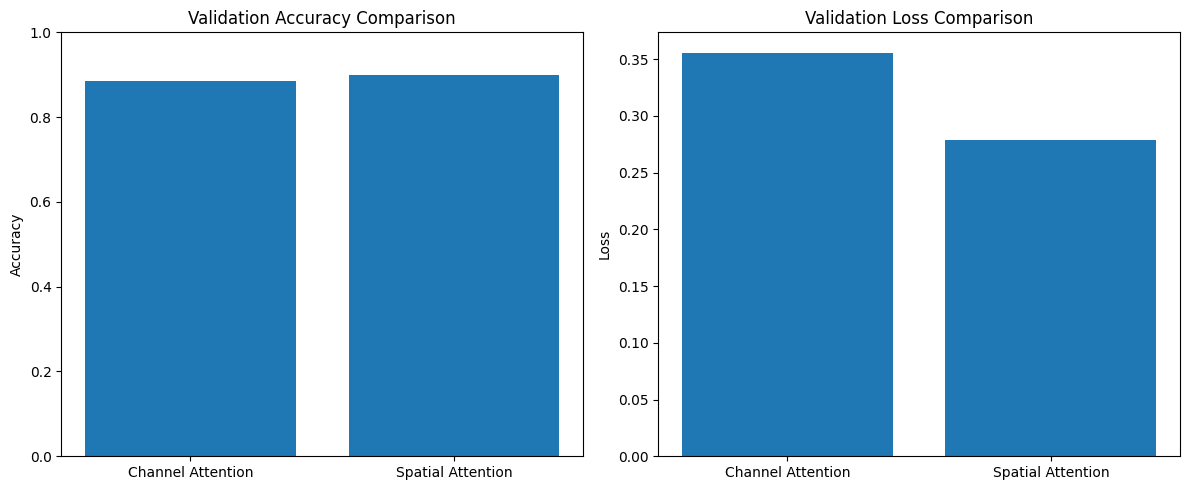

In [ ]:
import matplotlib.pyplot as plt

# Get final validation metrics
channel_accuracy = history.history["val_accuracy"][-1]
spatial_accuracy = spatial_history.history["val_accuracy"][-1]

channel_loss = history.history["val_loss"][-1]
spatial_loss = spatial_history.history["val_loss"][-1]

print("===== MODEL COMPARISON =====")
print(f"Channel Attention - Validation Accuracy: {channel_accuracy:.4f}")
print(f"Spatial Attention - Validation Accuracy: {spatial_accuracy:.4f}")
print(f"Channel Attention - Validation Loss:     {channel_loss:.4f}")
print(f"Spatial Attention - Validation Loss:     {spatial_loss:.4f}")

# Plot comparison
models = ["Channel Attention", "Spatial Attention"]

accuracies = [channel_accuracy, spatial_accuracy]
losses = [channel_loss, spatial_loss]

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.bar(models, accuracies)
plt.title("Validation Accuracy Comparison")
plt.ylabel("Accuracy")
plt.ylim(0, 1)

plt.subplot(1, 2, 2)
plt.bar(models, losses)
plt.title("Validation Loss Comparison")
plt.ylabel("Loss")

plt.tight_layout()
plt.show()

In [ ]:
import tensorflow as tf
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.layers import (
    Input,
    GlobalAveragePooling2D,
    Dense,
    Dropout
)
from tensorflow.keras.models import Model

# Input
inputs = Input(shape=(224, 224, 3))

# ResNet50 backbone
base_model_early = ResNet50(
    weights="imagenet",
    include_top=False,
    input_tensor=inputs
)

base_model_early.trainable = False

# Apply attention to an intermediate feature map
early_features = base_model_early.get_layer(
    "conv3_block4_out"
).output

early_features = channel_attention(early_features)

# Continue through the remaining ResNet50 layers
x = base_model_early.get_layer("conv4_block1_1_conv")(early_features)

# Use the original model's later layers to continue feature extraction
x = base_model_early.get_layer("conv4_block1_1_bn")(x)
x = base_model_early.get_layer("conv4_block1_1_relu")(x)

# Build a simpler, reliable early-attention variant using the intermediate features
x = GlobalAveragePooling2D()(early_features)
x = Dense(256, activation="relu")(x)
x = Dropout(0.5)(x)
outputs = Dense(5, activation="softmax")(x)

early_attention_model = Model(inputs=inputs, outputs=outputs)

early_attention_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

early_attention_model.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_3       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_pad           │ (None, 230, 230,  │          0 │ input_layer_3[0]… │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 112, 112,  │      9,472 │ conv1_pad[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 112, 112,  │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 112, 112,  │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pad           │ (None, 114, 114,  │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pool          │ (None, 56, 56,    │          0 │ pool1_pad[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 56, 56,    │      4,160 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 56, 56,    │        256 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 56, 56,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 56, 56,    │     36,928 │ conv2_block1_1_r… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_bn   │ (None, 56, 56,    │        256 │ conv2_block1_2_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_relu │ (None, 56, 56,    │          0 │ conv2_block1_2_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_conv │ (None, 56, 56,    │     16,640 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_conv │ (None, 56, 56,    │     16,640 │ conv2_block1_2_r… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_bn   │ (None, 56, 56,    │      1,024 │ conv2_block1_0_c… │
│ (BatchNormalizatio… │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_bn   │ (None, 56, 56,    │      1,024 │ conv2_block1_3_c

 Total params: 1,658,245 (6.33 MB)

 Trainable params: 198,149 (774.02 KB)

 Non-trainable params: 1,460,096 (5.57 MB)

In [ ]:
import tensorflow as tf
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.layers import (
    Input,
    GlobalAveragePooling2D,
    Dense,
    Dropout
)
from tensorflow.keras.models import Model

# Input
inputs = Input(shape=(224, 224, 3))

# Pretrained ResNet50
base_model_late = ResNet50(
    weights="imagenet",
    include_top=False,
    input_tensor=inputs
)

base_model_late.trainable = False

# Final ResNet50 feature maps
x = base_model_late.output

# Apply attention at the final feature-map position
x = channel_attention(x)

# Classification head
x = GlobalAveragePooling2D()(x)
x = Dense(256, activation="relu")(x)
x = Dropout(0.5)(x)
outputs = Dense(5, activation="softmax")(x)

# Create model
late_attention_model = Model(inputs=inputs, outputs=outputs)

# Compile
late_attention_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

late_attention_model.summary()

print("Late-attention model created successfully!")

Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_4       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_pad           │ (None, 230, 230,  │          0 │ input_layer_4[0]… │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 112, 112,  │      9,472 │ conv1_pad[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 112, 112,  │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 112, 112,  │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pad           │ (None, 114, 114,  │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pool          │ (None, 56, 56,    │          0 │ pool1_pad[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 56, 56,    │      4,160 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 56, 56,    │        256 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 56, 56,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 56, 56,    │     36,928 │ conv2_block1_1_r… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_bn   │ (None, 56, 56,    │        256 │ conv2_block1_2_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_relu │ (None, 56, 56,    │          0 │ conv2_block1_2_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_conv │ (None, 56, 56,    │     16,640 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_conv │ (None, 56, 56,    │     16,640 │ conv2_block1_2_r… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_bn   │ (None, 56, 56,    │      1,024 │ conv2_block1_0_c… │
│ (BatchNormalizatio… │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_bn   │ (None, 56, 56,    │      1,024 │ conv2_block1_3_c

 Total params: 25,162,117 (95.99 MB)

 Trainable params: 1,574,405 (6.01 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

Late-attention model created successfully!


In [ ]:
EPOCHS = 5

late_history = late_attention_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=32,
    verbose=1
)

print("Late-attention model training completed!")

Epoch 1/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 36s 261ms/step - accuracy: 0.8157 - loss: 0.5096 - val_accuracy: 0.8638 - val_loss: 0.3517
Epoch 2/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 12s 133ms/step - accuracy: 0.9206 - loss: 0.2407 - val_accuracy: 0.8978 - val_loss: 0.2724
Epoch 3/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 12s 135ms/step - accuracy: 0.9458 - loss: 0.1621 - val_accuracy: 0.9060 - val_loss: 0.2414
Epoch 4/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 12s 129ms/step - accuracy: 0.9608 - loss: 0.1194 - val_accuracy: 0.9169 - val_loss: 0.2368
Epoch 5/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 13s 137ms/step - accuracy: 0.9775 - loss: 0.0700 - val_accuracy: 0.9183 - val_loss: 0.2308
Late-attention model training completed!


            Model  Validation Accuracy  Validation Loss
Channel Attention             0.884196         0.355728
Spatial Attention             0.899183         0.278229
  Early Attention             0.222071         1.701911
   Late Attention             0.918256         0.230816


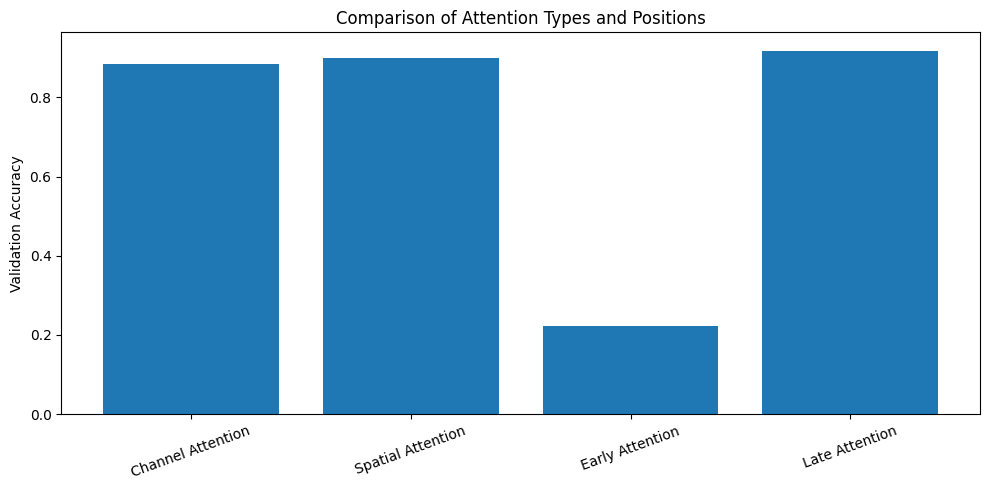

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

results = pd.DataFrame({
    "Model": [
        "Channel Attention",
        "Spatial Attention",
        "Early Attention",
        "Late Attention"
    ],
    "Validation Accuracy": [
        history.history["val_accuracy"][-1],
        spatial_history.history["val_accuracy"][-1],
        early_attention_model.evaluate(X_val, y_val, verbose=0)[1],
        late_history.history["val_accuracy"][-1]
    ],
    "Validation Loss": [
        history.history["val_loss"][-1],
        spatial_history.history["val_loss"][-1],
        early_attention_model.evaluate(X_val, y_val, verbose=0)[0],
        late_history.history["val_loss"][-1]
    ]
})

print(results.to_string(index=False))

# Plot validation accuracy
plt.figure(figsize=(10, 5))
plt.bar(results["Model"], results["Validation Accuracy"])
plt.title("Comparison of Attention Types and Positions")
plt.ylabel("Validation Accuracy")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [ ]:
results.to_csv("attention_experiment_results.csv", index=False)

print("Results saved to attention_experiment_results.csv")

Results saved to attention_experiment_results.csv
